# Fleet Reference: selective transfer, 5 October 2026

Actual checksum-reconciled **017, 024, 041, 058, 080, 081**, all eight Compressor modules.
This is an inspectable historical experiment, not a healthy-label dataset or Active model.
Private day partitions and output receipts must be supplied locally; they are excluded from Git.

The selected proposal freezes Local means/scales and borrows compatible **correlation shape**.
The fitted moments are a bounded Empirical-Bayes-style approximation; this notebook does not claim exact iid NIW, calibrated fault probability, or independent accuracy.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'apps/api').is_dir())
out = root / 'notebooks/outputs/fleet_reference_study_20261005'
summary = json.loads((out/'summary.json').read_text(encoding='utf-8'))
manifest = json.loads((out/'intake_manifest.json').read_text(encoding='utf-8'))
qa = json.loads((out/'technical-qa.json').read_text(encoding='utf-8'))
assert summary['study_id'] == qa['study_id']
print('Frozen study:', summary['study_id'])
print('Protocol:', json.dumps(summary['protocol'], indent=2))

Frozen study: d907db2e9e283e7183d252b3
Protocol: {
  "version": "selective-fleet-empirical-bayes-v1",
  "source_clock": "Asia/Bangkok, naive original DATETIME interpretation",
  "source_period": [
    "2026-07-01",
    "2026-10-02"
  ],
  "reference": [
    "2026-07-02",
    "2026-08-15"
  ],
  "calibration": [
    "2026-08-15",
    "2026-08-22"
  ],
  "diagnostic": [
    "2026-09-01",
    "2026-10-01"
  ],
  "sparse_days": [
    1,
    3,
    7,
    14
  ],
  "features": [
    "hp1",
    "lp1",
    "hp2",
    "lp2",
    "temphi",
    "templo"
  ],
  "sample_spacing_minutes": 15,
  "stability_trailing_minutes": 5,
  "stability_limit": 0.35,
  "threshold_quantile": 0.995,
  "stability_definition": "physical max-minus-min over five contiguous supported minutes, normalized by Reference scale",
  "minimum_threshold_points": 200,
  "minimum_threshold_days": 3,
  "seed": 17,
  "transfer_center_rms_max": 1.5,
  "transfer_correlation_distance_max": 0.5,
  "transfer_min_target_points": 20,
  "m

## Source quality and coverage

555 committed dynamic files, July 1–October 1 inclusive. July 1 is absent from the imported scope for 041/058/080. October 2–5 files and older SQL fixtures are outside the corpus. Duplicate counts below count rows participating in duplicated timestamps, not distinct duplicate keys. A passing minute is a complete observation, not a normal/healthy label. No missing seconds are interpolated.

In [2]:
files = pd.DataFrame(manifest['files'])
display(files.groupby('machine').agg(files=('date','count'), raw_rows=('raw_rows','sum'),
    duplicate_occurrence_rows=('duplicate_rows','sum'), invalid_valves=('invalid_valve_observations','sum')))
display(pd.DataFrame(summary['coverage'])[['machine','module','source_days','quality_minutes','sv_off_minutes','sv_on_minutes']])
print('Partial files below 80,000 rows (screen only):')
display(files.loc[files.raw_rows.lt(80000), ['machine','date','raw_rows','source_sha256']])

,files,raw_rows,duplicate_occurrence_rows,invalid_valves
machine,,,,
017,93,7772969,40617,0
024,93,7801416,13143,0
041,92,7758001,21550,0
058,92,7751066,25080,0
080,92,7687891,4202,0
081,93,7845141,1334,0


,machine,module,source_days,quality_minutes,sv_off_minutes,sv_on_minutes
0,017,1,93,126728,105792,3779
1,017,2,93,126728,106124,3792
2,017,3,93,126728,105951,3797
3,017,4,93,126728,106130,12767
4,017,5,93,126728,106046,3445
5,017,6,93,126728,106070,3415
6,017,7,93,126728,0,0
7,017,8,93,126728,106027,3412
8,024,1,93,128434,100734,337
9,024,2,93,128434,100772,343


Partial files below 80,000 rows (screen only):


,machine,date,raw_rows,source_sha256
3,017,2026-07-04,66757,822446ece5e199838d060a18ddc71e1c1afc5ad896d02d...
5,017,2026-07-06,78738,7b792bdcf4f78c1b2cc9899674edacadb2135c9b9debc5...
15,017,2026-07-16,68430,a08216c78a50785795c68ba7affa5aa42313d540224fab...
42,017,2026-08-12,6077,53ba1bc5cb3610f15b01aa2aeb5bd7b790ca24c7cd78f1...
92,017,2026-10-01,56508,cecb0b4b20ce5b7a77d7303e76dd848532fde809f89b5d...
135,024,2026-08-12,9823,6ce3a09566cf7064645de9c8dfeaa6699cefed74ab2ae7...
144,024,2026-08-21,67474,c91a3b502984e0717623ff405f49ef49cc477532b0fb95...
185,024,2026-10-01,55916,03f9c68398b9e5c0853fc7c9714f0ffb8ab6770eae91ea...
227,041,2026-08-12,7236,af70de0a09136e2841e7e515f26f1cc87740f8679eeb40...
319,058,2026-08-12,6947,6c8766a075845d19c6f7585c3ebc244662622cdb127825...


## Time and asset separation

Reference: July 2–August 14. Threshold calibration: August 15–21. Historical diagnostics: September 1–30. Endpoints in the protocol are exclusive. Sparse arms vary **Fit** history (1/3/7/14 days) and additionally need seven target calibration days: this is not a pure one-day cold start.

The entire target machine is excluded from its donors. Same M index is an unverified research stratum; source logs do not contain an independently verified ATC mode/hardware/configuration contract. SV-conditioned stable segments can still contain multiple operating regimes and require review.

In [3]:
variants = pd.DataFrame(summary['variants'])
display(variants.groupby(['machine','status']).size().unstack(fill_value=0))
completed = variants[variants.status.eq('RESEARCH_PROPOSAL')].copy()
display(completed.groupby('machine').agg(scenarios=('module','count'),
    full_pool_compatible=('fleet_weight',lambda s: s.gt(0).sum()),
    shape_pool_compatible=('relationship_fleet_weight',lambda s:s.gt(0).sum())))
display(completed[completed.fit_days_requested.eq(14)][['machine','module','context','fit_points',
    'fit_days_observed','relationship_donor_machines','relationship_fleet_weight']])
print('Compatibility counts are NOT detection accuracy or accepted Active Profiles.')

status,INSUFFICIENT_DISJOINT_CALIBRATION,INSUFFICIENT_FIT,RESEARCH_PROPOSAL
machine,,,
017,8,50,6
024,7,52,5
041,8,37,19
058,6,34,24
080,5,35,24
081,7,34,23


,scenarios,full_pool_compatible,shape_pool_compatible
machine,,,
017,6,0,3
024,5,0,3
041,19,0,14
058,24,0,13
080,24,0,22
081,23,0,21


,machine,module,context,fit_points,fit_days_observed,relationship_donor_machines,relationship_fleet_weight
3,017,1,SV_OFF,130.0,10.0,[080],0.000000
11,017,2,SV_OFF,171.0,10.0,[041],0.000000
19,017,3,SV_OFF,420.0,10.0,"[024, 041, 058, 080, 081]",0.044078
27,017,4,SV_OFF,65.0,10.0,[],0.000000
35,017,5,SV_OFF,112.0,10.0,"[024, 041, 058, 080, 081]",0.136710
43,017,6,SV_OFF,340.0,10.0,"[080, 081]",0.058172
67,024,1,SV_OFF,18.0,10.0,[],0.000000
83,024,3,SV_OFF,122.0,10.0,"[017, 041, 058, 081]",0.146853
91,024,4,SV_OFF,83.0,10.0,"[017, 041, 058, 080, 081]",0.174379
131,041,1,SV_OFF,300.0,14.0,"[058, 081]",0.065421


Compatibility counts are NOT detection accuracy or accepted Active Profiles.


## Observed SV / Valve response

Every within-day observed command/state change is retained in the day event partitions. First rows have no invented preceding-day witness. Diagnostics use all usable SV changes and a deterministic subset of Valve steps ≥3 units, separated by two hours. These examples may have concurrent controls; settling is not proven health or causal response. Censored/unsettled/no-response events remain in the denominator. Five-minute stable observation is sought only after material response; no fixed exclusion timer is deployed.

In [4]:
events = pd.read_parquet(out/'transition_metrics.parquet')
display(events.groupby(['event_type','split','status']).size().rename('events').reset_index())
phase = pd.DataFrame(summary['transition_summary'])
display(phase[(phase.machine.isin(['041','058','080','081'])) & phase.direction.isin(['OFF_TO_ON','ON_TO_OFF'])])

,event_type,split,status,events
0,SV_CHANGED,calibration,CENSORED_OR_UNSETTLED,72
1,SV_CHANGED,calibration,INSUFFICIENT_PRE_EVENT,343
2,SV_CHANGED,calibration,NO_COMPLETE_POST_EVENT,22
3,SV_CHANGED,calibration,NO_MATERIAL_RESPONSE_OBSERVED,1
4,SV_CHANGED,calibration,SETTLED_OBSERVATION,7
5,SV_CHANGED,diagnostic,CENSORED_OR_UNSETTLED,265
6,SV_CHANGED,diagnostic,INSUFFICIENT_PRE_EVENT,1751
7,SV_CHANGED,diagnostic,NO_COMPLETE_POST_EVENT,74
8,SV_CHANGED,diagnostic,NO_MATERIAL_RESPONSE_OBSERVED,5
9,SV_CHANGED,diagnostic,SETTLED_OBSERVATION,64


,machine,module,direction,split,events,settled_observations,censored_or_insufficient,settling_p50_minutes,settling_p90_minutes,response_delay_p50_minutes,healthy_label_verified
436,041,1,OFF_TO_ON,calibration,7,0,7,NaN,NaN,0.0,False
437,041,1,OFF_TO_ON,diagnostic,1,0,1,NaN,NaN,NaN,False
438,041,1,OFF_TO_ON,outside_evaluation,33,0,33,NaN,NaN,0.0,False
439,041,1,OFF_TO_ON,reference,22,0,22,NaN,NaN,0.0,False
440,041,1,ON_TO_OFF,calibration,7,0,7,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...
1202,081,8,OFF_TO_ON,reference,44,0,44,NaN,NaN,0.0,False
1203,081,8,ON_TO_OFF,calibration,1,0,1,NaN,NaN,NaN,False
1204,081,8,ON_TO_OFF,diagnostic,18,0,18,NaN,NaN,0.0,False
1205,081,8,ON_TO_OFF,outside_evaluation,3,0,3,NaN,NaN,NaN,False


## Previously inspected MX080/M6 case

The owner-confirmed interval begins September 7 at 12:23:28. Complete incident minutes start 12:24. All-state observed minute averages below are not raw seconds. The frozen Local candidate baseline stays visible when a shifted level later becomes flat. This regression uses qualified/control-supported/steady minutes only, so it is not a claim of full-episode coverage or prospective recall.

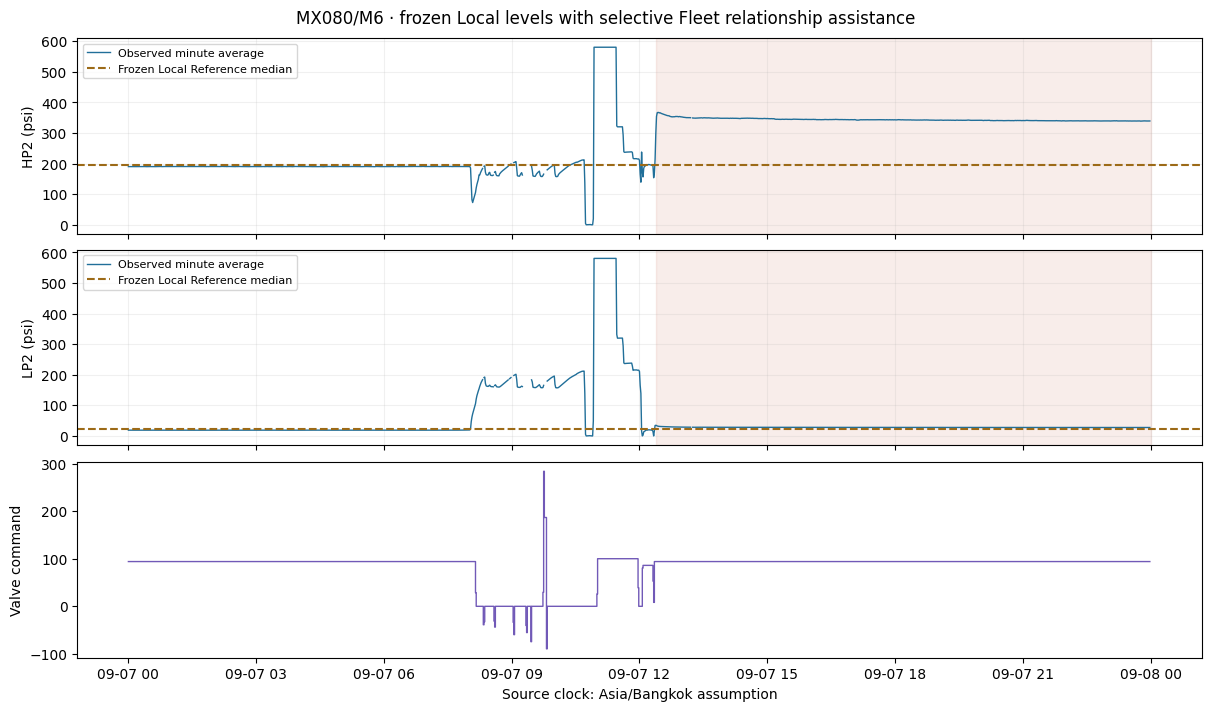

,context,quality_supported_steady_minutes,absolute_flags,relationship_flags,combined_flags,combined_persistent_minutes,fleet_weight,local_level_frozen,local_scale_frozen
0,SV_OFF,643,643,643,643,629,0.023022,True,True


In [5]:
models=json.loads((out/'model_proposals.json').read_text(encoding='utf-8'))['models']
model=next(m for m in models if m['machine']=='080' and m['module']==6 and m['context']=='SV_OFF')
data=pd.read_parquet(out/'minutes/080_2026-09-07.parquet',filters=[('module','==',6)]).sort_values('time')
fig,axes=plt.subplots(3,1,figsize=(12,7),sharex=True,layout='constrained')
for ax,feature,label,index in [(axes[0],'hp2','HP2 (psi)',2),(axes[1],'lp2','LP2 (psi)',3)]:
    observed=data[feature].where(data.quality)
    # Add NaN breakpoints for gaps, rather than drawing across absent minutes.
    observed=pd.Series(observed.to_numpy(),index=data.time).reindex(pd.date_range(data.time.min(),data.time.max(),freq='min'))
    ax.plot(observed.index,observed.values,color='#216f99',lw=1,label='Observed minute average')
    ax.axhline(model['center'][index],color='#9c6a17',ls='--',label='Frozen Local Reference median')
    ax.axvspan(pd.Timestamp('2026-09-07 12:23:28'),pd.Timestamp('2026-09-08'),color='#cc6d54',alpha=.12)
    ax.set_ylabel(label);ax.grid(alpha=.18);ax.legend(loc='upper left',fontsize=8)
axes[2].step(data.time,data.valve,where='post',color='#7159b7',lw=1)
axes[2].set_ylabel('Valve command');axes[2].set_xlabel('Source clock: Asia/Bangkok assumption')
fig.suptitle('MX080/M6 · frozen Local levels with selective Fleet relationship assistance')
fig.savefig(out/'known-case-local-levels.png',dpi=150)
plt.show()
display(pd.DataFrame(qa['known_case']['results']))

## Performance, mutation boundary and reproduction

HTTP measurements are bounded prepared-artifact reads, not live SQL intake or browser rendering. Batch-score time excludes IO, fit and approval. Wire cache now retains 128 immutable views with the same 32 MB cap; mutable Raw cache remains 24 entries. API requests never trigger model fitting. Model proposals are nonvoting and not auto-activated.

Reproduce from the workspace root with the existing local environment:
```text
python -m notebooks.support.fleet_reference_study --intake
python -m notebooks.support.fleet_reference_benchmark
python notebooks/support/fleet_reference_qa.py
```
Intake validates committed SHA/row-count receipts; it does not resume the stopped source import. The QA command needs the local API at port 8000. See deployment/FLEET_REFERENCE_AND_SELECTIVE_TRANSFER_UAT_20261005.md for real-browser results and activation prerequisites.

In [6]:
display(pd.DataFrame([qa['scoring']]))
display(pd.DataFrame([{k:v for k,v in qa['http'].items() if k not in ['first_reads','responses']}]))
print('Actual execution environment:',qa['environment'])
print('Registry receipts:',json.dumps(qa['registry'],indent=2))
assert all(qa['registry'][table]['unchanged'] for table in ['ht9046mx_calibration_profile','ht9046mx_active_calibration_profile'])
assert summary['activation_eligible'] is False
print('Independent healthy-cycle/future validation, verified contracts and reviewed regime references remain required.')

,actual_points,repeats,p50_ms,p95_ms,interpretation
0,1361,30,0.14175,0.243345,"In-process batch numerical score only, exclude..."


,clients,requests,successes,first_read_clients,first_p95_ms,p50_ms,p95_ms,max_ms,invalid_day_and_module,interpretation
0,10,120,120,4,224.544015,53.10055,109.014405,120.9961,"[422, 422]","Prepared artifact GETs only, not live SQL inta..."


Actual execution environment: {'python': '3.12.10', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy': '2.2.1', 'pandas': '2.2.3', 'thread_policy': 'OPENBLAS=1 OMP=1, intake POLARS=2'}
Registry receipts: {
  "ht9046mx_calibration_profile": {
    "rows": 207,
    "sha256": "04c30ac95a435e3345041f5015518624d7c3075112c9708b7d8689fa6d28e5d5",
    "unchanged": true
  },
  "ht9046mx_active_calibration_profile": {
    "rows": 46,
    "sha256": "7f05d8a04d3c01a3f0a4513592d1200c8d2096449187ce38ed866ba51f377be1",
    "unchanged": true
  },
  "context_active_count": 0,
  "import_receipt_count": 567
}
Independent healthy-cycle/future validation, verified contracts and reviewed regime references remain required.
